In [1]:
# Import libraries. You may or may not use all of these.
!pip install -q git+https://github.com/tensorflow/docs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
  # %tensorflow_version only exists in Colab.
  %tensorflow_version 2.x
except Exception:
  pass
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

import tensorflow_docs as tfdocs
import tensorflow_docs.plots
import tensorflow_docs.modeling

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.13/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

I0000 00:00:1792528424.123721  250585 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792528424.178814  250585 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792528425.260957  250585 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Import data
!wget -nc -q https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv
dataset = pd.read_csv('insurance.csv')
dataset.tail()

,age,sex,bmi,children,smoker,region,expenses
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95
1337,61,female,29.1,0,yes,northwest,29141.36


In [3]:
# Convert categorical data to numbers
dataset['sex'] = (dataset['sex'] == 'male').astype(int)
dataset['smoker'] = (dataset['smoker'] == 'yes').astype(int)
dataset = pd.get_dummies(dataset, columns=['region'], prefix='', prefix_sep='', dtype=int)
dataset = dataset.astype('float32')
dataset.tail()

,age,sex,bmi,children,smoker,expenses,northeast,northwest,southeast,southwest
1333,50.0,1.0,31.000000,3.0,0.0,10600.549805,0.0,1.0,0.0,0.0
1334,18.0,0.0,31.900000,0.0,0.0,2205.979980,1.0,0.0,0.0,0.0
1335,18.0,0.0,36.900002,0.0,0.0,1629.829956,0.0,0.0,1.0,0.0
1336,21.0,0.0,25.799999,0.0,0.0,2007.949951,0.0,0.0,0.0,1.0
1337,61.0,0.0,29.100000,0.0,1.0,29141.359375,0.0,1.0,0.0,0.0


In [4]:
# Split: 80% train / 20% test
train_dataset = dataset.sample(frac=0.8, random_state=0)
test_dataset = dataset.drop(train_dataset.index)

# Pop off the "expenses" column to create the labels
train_labels = train_dataset.pop('expenses')
test_labels = test_dataset.pop('expenses')

print(len(train_dataset), 'train rows /', len(test_dataset), 'test rows')

1070 train rows / 268 test rows


In [5]:
# Build and train the model
tf.keras.utils.set_random_seed(0)

normalizer = layers.Normalization(axis=-1)
normalizer.adapt(np.array(train_dataset))

model = keras.Sequential([
    keras.Input(shape=(train_dataset.shape[1],)),
    normalizer,
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
              loss='mae',
              metrics=['mae', 'mse'])
model.summary()

history = model.fit(
    train_dataset, train_labels,
    epochs=300,
    validation_split=0.2,
    verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True)]
)
print('Epochs trained:', len(history.history['loss']))
print('Final validation MAE: {:.2f}'.format(min(history.history['val_mae'])))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,884 (19.08 KB)

 Trainable params: 4,865 (19.00 KB)

 Non-trainable params: 19 (80.00 B)

Epochs trained: 300
Final validation MAE: 1511.70


9/9 - 0s - 4ms/step - loss: 2139.5034 - mae: 2139.5034 - mse: 33553286.0000


Testing set Mean Abs Error: 2139.50 expenses
You passed the challenge. Great job!
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


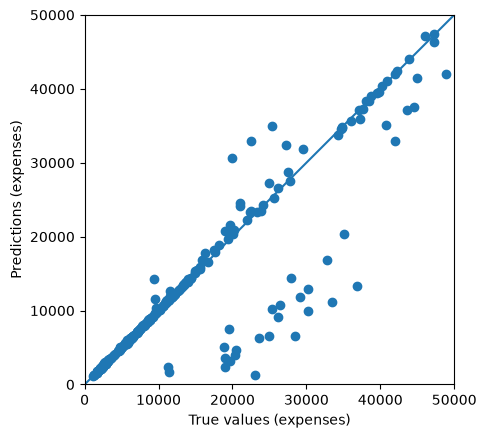

In [6]:
# RUN THIS CELL TO TEST YOUR MODEL. DO NOT MODIFY CONTENTS.
# Test model by checking how well the model generalizes using the test set.
loss, mae, mse = model.evaluate(test_dataset, test_labels, verbose=2)

print("Testing set Mean Abs Error: {:5.2f} expenses".format(mae))

if mae < 3500:
  print("You passed the challenge. Great job!")
else:
  print("The Mean Abs Error must be less than 3500. Keep trying.")

# Plot predictions.
test_predictions = model.predict(test_dataset).flatten()

a = plt.axes(aspect='equal')
plt.scatter(test_labels, test_predictions)
plt.xlabel('True values (expenses)')
plt.ylabel('Predictions (expenses)')
lims = [0, 50000]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims,lims)
